# Setup

In [1]:
# Libraries
%load_ext autoreload
%autoreload 2

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from PIL import Image
import base64
from io import BytesIO
from typing import List, Optional
import torchvision.utils as vutils
import torch

# --- Colorcet and Bokeh Imports ---
import colorcet as cc
from bokeh.plotting import figure
from bokeh.models import HoverTool, ColumnDataSource, Span, LinearColorMapper, ColorBar 
from bokeh.io import output_notebook, show, output_file, save
import pandas.api.types as ptypes

# --- Custom packages ---
from compcats.datasets.fmri import nsd
from compcats.datasets.fmri.utils import nsd_ds_utils
from compcats.utils import model_utils, coco_utils, responsecomparison_utils as rc_utils
import main_analysis as ma
import paths

# Paths
RESULTS_DIR = 'results/exploration/explore_interpret'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/'
os.makedirs(PLOTS_DIR, exist_ok=True)
NSD_DIR = paths.NSD_DIR
GRILLSPECTOR_LOCALIZER_DIR = paths.GRILLSPECTOR_LOCALIZER_DIR
COCO_ANNOTATIONS_PATH = paths.COCO_ANNOTATIONS_PATH

# Plot settings
import matplotlib as mpl
from matplotlib import rcParams
rcParams.update({'figure.autolayout': False})
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
# Font
font_path = '/home/alishd/.fonts/Avenir.ttc'
avenir_font = mpl.font_manager.FontProperties(fname=font_path)
mpl.rcParams['font.family'] = avenir_font.get_name()
ttc = mpl.font_manager.get_font(font_path)
print("Font name from TTC:", ttc.family_name)
print("Style:", ttc.style_name)

Font name from TTC: Avenir
Style: Book


In [2]:
# Plotting (Bokeh) Utils

def numpy_to_base64(img_array: np.ndarray, thumbnail_size: Optional[tuple] = None) -> str:
    """Converts a NumPy array to a Base64 string for embedding in HTML."""
    if img_array.dtype != np.uint8:
        img_array = img_array.astype(np.uint8)
    img = Image.fromarray(img_array)
    if thumbnail_size:
        img.thumbnail(thumbnail_size)
    with BytesIO() as buffer:
        img.save(buffer, format="PNG")
        byte_data = buffer.getvalue()
        base64_str = base64.b64encode(byte_data).decode('utf-8')
    return base64_str

def save_interactive_plot_as_html(
    plot: figure,
    output_path: str
):
    """
    Saves a Bokeh plot as an HTML file.

    Args:
        plot (bokeh.plotting.figure): The Bokeh figure to save.
        output_path (str): The file path to save the HTML file to.
    """
    output_file(output_path, title=plot.title.text)
    save(plot)
    print(f"Plot saved to '{output_path}'")
    return None

def plot_scatter_with_image_hover(
    df: pd.DataFrame,
    images_np: np.ndarray,
    x_col: str,
    y_col: str,
    color_col: str,
    info_cols: Optional[List[str]] = None,
    output_path: Optional[str] = None,
    title: str = "Interactive Scatter Plot with Image Tooltips",
    tooltip_img_size: int = 120
):
    """
    Creates an interactive Bokeh scatter plot with image tooltips on hover.
    Uses a symmetric colorcet.coolwarm color bar centered at 0.
    """
    # --- 1. Input Validation and Data Preparation ---
    assert len(df) == len(images_np), "DataFrame and images_np array must have the same length."
    df_plot = df.copy()
    if info_cols is None: info_cols = []
    for col in info_cols:
        if col in df_plot.columns and not df_plot[col].dropna().empty:
            first_item = df_plot[col].dropna().iloc[0]
            if isinstance(first_item, (list, np.ndarray)):
                df_plot[col] = df_plot[col].apply(lambda x: ', '.join(map(str, x)) if isinstance(x, (list, np.ndarray)) else x)
    
    df_plot['image_b64'] = [numpy_to_base64(img, thumbnail_size=(256, 256)) for img in images_np]
    source = ColumnDataSource(data=df_plot)

    # --- 2. Dynamically Create Tooltip HTML (Unchanged) ---
    info_html = ""
    for col in info_cols:
        label = col.replace('_', ' ').title()
        formatter = "{0.00}" if ptypes.is_numeric_dtype(df_plot[col].dtype) else ""
        info_html += f'<div><span style="font-size: 12px; font-weight: bold;">{label}:</span> <span style="font-size: 12px; color: #555555;">@{col}{formatter}</span></div>'
    TOOLTIP_HTML = f"""
        <div style="padding: 5px; border: 1px solid #cccccc; width: {tooltip_img_size + 20}px;">
            <div><img src="data:image/png;base64,@image_b64" style="margin: 5px; width:{tooltip_img_size}px; height:{tooltip_img_size}px; border: 1px solid #dddddd;"></div>
            {info_html}
            <div><span style="font-size: 12px; font-weight: bold;">Location:</span> <span style="font-size: 12px; color: #555555;">(@{x_col}, @{y_col})</span></div>
        </div>
    """

    # --- 3. Create the Plot ---
    print("Creating Bokeh plot...")
    hover = HoverTool(tooltips=TOOLTIP_HTML)
    
    # Find the maximum absolute value to create a symmetric range
    c_min = df_plot[color_col].min()
    c_max = df_plot[color_col].max()
    limit = max(abs(c_min), abs(c_max))
    if limit == 0: limit = 1 # Avoid a zero-width range if all values are 0
    
    mapper = LinearColorMapper(
        palette=cc.coolwarm, 
        low=-limit, 
        high=limit
    )
    
    p = figure(width=800, height=600, tools=[hover, 'pan', 'wheel_zoom', 'box_zoom', 'reset', 'save'], title=title, x_axis_label=x_col, y_axis_label=y_col)
    p.grid.visible = False
    hline = Span(location=0, dimension='width', line_color='gray', line_dash='dashed', line_width=1.5)
    p.add_layout(hline)
    vline = Span(location=0, dimension='height', line_color='gray', line_dash='dashed', line_width=1.5)
    p.add_layout(vline)
    min_val, max_val = min(df_plot[x_col].min(), df_plot[y_col].min()) - 5, max(df_plot[x_col].max(), df_plot[y_col].max()) + 5
    p.line([min_val, max_val], [min_val, max_val], color="gray", line_dash="dashed", line_width=1.5)
    
    p.scatter(x=x_col, y=y_col, source=source, size=10, color={'field': color_col, 'transform': mapper}, fill_alpha=0.7, line_color="gray", line_alpha=0.2)
    
    color_bar = ColorBar(color_mapper=mapper, label_standoff=12, location=(0,0), title=color_col)
    p.add_layout(color_bar, 'right')
    
    # --- 4. Output Handling ---
    if output_path:
        output_file(output_path, title=title)
        save(p)
        print(f"Plot saved to '{output_path}'")
    else:
        output_notebook()
        show(p)
        
    return p

In [3]:
# Data utils

def get_data(
    subject: int,
    froi: str,
    subset: int | None, # 515 for shared, None for subject-specific set
    model_name: str,
    nsdids: Optional[List[int]] = None
):
    tthreshold = 7
    model_localizer = 'grillspector'
    model_localizer_dir = GRILLSPECTOR_LOCALIZER_DIR
    # Get model and layer
    model = ma.get_model(model_name)
    layer = ma.get_froi_models_layers(froi, froi)[model_name]
    # Subject data
    subject_data, images_df = nsd.get_betas(
        NSD_DIR, subject, froi, tthreshold, subset=subset, voxels=True
    )
    # Model data
    model_data = model_utils.get_dataset_activations(
        MODELS_DIR, NSD_DIR, model, layer, 'nsd', froi, tthreshold, subset=subset,
        froi_localizer=model_localizer, froi_localizer_dir=model_localizer_dir, device='cpu'
    )
    # Stimuli
    stimuli = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=subset).all_stimuli
    # Add info to images_df
    images_df = coco_utils.add_image_info_to_df(images_df, COCO_ANNOTATIONS_PATH)
    # Choose subject-specific images if needed
    if subset is None:
        shared1000_nsdids = nsd_ds_utils.get_subset_nsdids(paths.NSD_DIR, 1000)
        subject_data = subject_data[~images_df['nsdId'].isin(shared1000_nsdids)]
        images_df = images_df[~images_df['nsdId'].isin(shared1000_nsdids)].reset_index(drop=True)
        subject_nsdids = images_df['nsdId'].values
        stimuli = stimuli[subject_nsdids]
        model_data = model_data[subject_nsdids]

    # Get correlations for validation
    pearsonr = rc_utils.pearsonr(
        subject_data.mean(axis=-1), model_data.mean(axis=-1)
    )
    rdmr = rc_utils.rdmr(subject_data, model_data)
    print(f"Full subset, \nMean Pearson r: {pearsonr:.4f}, RDMR: {rdmr:.4f}")

    # Store Voxel/Unit-averaged responses
    subject_data_mean = subject_data.mean(axis=-1).cpu().numpy()
    model_data_mean = model_data.mean(axis=-1).cpu().numpy()
    ## Also store z-scored versions
    subject_data_mean_zscored = (subject_data_mean - subject_data_mean.mean()) / subject_data_mean.std()
    model_data_mean_zscored = (model_data_mean - model_data_mean.mean()) / model_data_mean.std()

    if nsdids is not None:
        subject_data_mean_nsdid_subset = subject_data_mean[np.isin(images_df['nsdId'].values, nsdids)]
        model_data_mean_nsdid_subset = model_data_mean[np.isin(images_df['nsdId'].values, nsdids)]
        subject_data_mean_zscored_nsdid_subset = subject_data_mean_zscored[np.isin(images_df['nsdId'].values, nsdids)]
        model_data_mean_zscored_nsdid_subset = model_data_mean_zscored[np.isin(images_df['nsdId'].values, nsdids)]
        # Get correlations for validation
        pearsonr_mean = rc_utils.pearsonr(
            torch.tensor(subject_data_mean_nsdid_subset),
            torch.tensor(model_data_mean_nsdid_subset)
        )
        pearsonr_mean_zscored = rc_utils.pearsonr(
            torch.tensor(subject_data_mean_zscored_nsdid_subset), 
            torch.tensor(model_data_mean_zscored_nsdid_subset)
        )
        print(f"nsd ID subset mean, \nMean Pearson r: {pearsonr_mean:.4f}, Z-scored Pearson r: {pearsonr_mean_zscored:.4f}")

        subject_data_mean_zscored = subject_data_mean_zscored_nsdid_subset
        model_data_mean_zscored = model_data_mean_zscored_nsdid_subset

        nsdid_indices = np.isin(images_df['nsdId'].values, nsdids)
        subject_data = subject_data[nsdid_indices]
        stimuli = stimuli[nsdid_indices]
        model_data = model_data[nsdid_indices]
        images_df = images_df[nsdid_indices].reset_index(drop=True)

    mean_responses_df = pd.DataFrame({
        'idx': images_df.index,
        'nsd_image_id': images_df['nsdId'],
        'subject_response': subject_data_mean_zscored,
        'model_response': model_data_mean_zscored,
        'response_diff': subject_data_mean_zscored - model_data_mean_zscored,
        'labels': images_df['labels'],
    })
    return mean_responses_df, images_df, stimuli, subject_data, model_data

# FFA (s1 vs. RN50-ImgNet)

### Voxel/Unit-averaged responses: 515 images

In [ ]:
subject = 1
froi = 'FFA'
subset = 515 # 515 for shared, None for subject-specific set
model_name = 'resnet50imagenet1kv2'

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
)

sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
    df=sbj_froi_mdl_subset_resp_df,
    images_np=stimuli_subset,
    x_col='model_response',
    y_col='subject_response',
    color_col='response_diff',
    info_cols=['labels', 'nsd_image_id'],
    output_path=None,  # Change to a file path to save as HTML
    title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
)

save_interactive_plot_as_html(
    plot=sbj_froi_mdl_subset_scatter,
    output_path=f'{PLOTS_DIR}/s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
)

In [ ]:
subject = 1
froi = 'FFA'
subset = 515 # 515 for shared, None for subject-specific set
model_name = 'resnet50openaiclip'

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
)

sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
    df=sbj_froi_mdl_subset_resp_df,
    images_np=stimuli_subset,
    x_col='model_response',
    y_col='subject_response',
    color_col='response_diff',
    info_cols=['labels', 'nsd_image_id'],
    output_path=None,  # Change to a file path to save as HTML
    title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
)

save_interactive_plot_as_html(
    plot=sbj_froi_mdl_subset_scatter,
    output_path=f'{PLOTS_DIR}/s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
)

In [ ]:
subject = 1
froi = 'FFA'
subset = 515 # 515 for shared, None for subject-specific set
model_name = 'alexnetipclref01'

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
)

sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
    df=sbj_froi_mdl_subset_resp_df,
    images_np=stimuli_subset,
    x_col='model_response',
    y_col='subject_response',
    color_col='response_diff',
    info_cols=['labels', 'nsd_image_id'],
    output_path=None,  # Change to a file path to save as HTML
    title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
)

save_interactive_plot_as_html(
    plot=sbj_froi_mdl_subset_scatter,
    output_path=f'{PLOTS_DIR}/s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
)

#### Dev

In [ ]:
subject = 1
froi = 'FFA'
tthreshold = 7
subset = 515 # None for full subject-specific set

model_name = 'resnet50imagenet1kv2'
model = ma.get_model(model_name)
layer = ma.get_froi_models_layers(froi, froi)[model_name]
model_localizer = 'grillspector'
model_localizer_dir = GRILLSPECTOR_LOCALIZER_DIR

# Subject data
subject_data, images_df = nsd.get_betas(
    NSD_DIR, subject, froi, tthreshold, subset=subset, voxels=True
)
if subset is None:
    raise NotImplementedError("Implement getting only subject-specific data")
# Model data
model_data = model_utils.get_dataset_activations(
    MODELS_DIR, NSD_DIR, model, layer, 'nsd', froi, tthreshold, subset=subset,
    froi_localizer=model_localizer, froi_localizer_dir=model_localizer_dir, device='cpu'
)
# Stimuli
stimuli = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=subset).all_stimuli
# Add info to images_df
images_df = coco_utils.add_image_info_to_df(images_df, COCO_ANNOTATIONS_PATH)

# Print shapes for valiation
print("Subject data shape:", subject_data.shape)
print("Model data shape:", model_data.shape)
print("Stimuli shape:", stimuli.shape)

# Get correlations for validation
pearsonr = rc_utils.pearsonr(
    subject_data.mean(axis=-1), model_data.mean(axis=-1)
)
rdmr = rc_utils.rdmr(subject_data, model_data)
print(f"\nMean Pearson r: {pearsonr:.4f}, RDMR: {rdmr:.4f}")

# Store Voxel/Unit-averaged responses
subject_data_mean = subject_data.mean(axis=-1).cpu().numpy()
model_data_mean = model_data.mean(axis=-1).cpu().numpy()
## Also store z-scored versions
subject_data_mean_zscored = (subject_data_mean - subject_data_mean.mean()) / subject_data_mean.std()
model_data_mean_zscored = (model_data_mean - model_data_mean.mean()) / model_data_mean.std()

mean_responses_df = pd.DataFrame({
    'idx': images_df.index,
    'nsd_image_id': images_df['nsdId'],
    'subject_response': subject_data_mean_zscored,
    'model_response': model_data_mean_zscored,
    'response_diff': subject_data_mean_zscored - model_data_mean_zscored,
    'labels': images_df['labels'],
})
# mean_responses_df.to_csv(f'{RESULTS_DIR}/mean_responses_{froi}_subj{subject}_{model_name}.csv', index=False)

min_value, max_value = -1.5, 1.5

plt.figure(figsize=(10, 10))
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.axvline(0, color='gray', linestyle='--', linewidth=1)

# Create scatter plot with diverging colormap
scatter = plt.scatter(
    mean_responses_df['model_response'], mean_responses_df['subject_response'], 
    c=mean_responses_df['response_diff'], cmap='RdBu_r', 
    ec='none', alpha=0.8
)

plt.ylabel('Subject mean z-scored voxel response', fontsize=14)
plt.xlabel(f'Model {model.name} mean z-scored unit response', fontsize=14)
plt.title(f'Scatter of mean z-scored responses {froi} (t>{tthreshold})\nSubject {subject} vs. {model.name} {layer}', fontsize=16)
# Make y=x line
plt.plot([min_value, max_value], [min_value, max_value], color='gray', linestyle='--', linewidth=1)
plt.xlim((min_value, max_value))
plt.ylim((min_value, max_value))

# Add colorbar
cbar = plt.colorbar(scatter)
cbar.set_label('Subject - Model response difference', fontsize=12)
plt.gca().set_aspect('equal', adjustable='box')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(min_value, max_value)
plt.gca().spines['left'].set_bounds(min_value, max_value)
plt.ylim(plt.ylim()[0], plt.ylim()[1] + 0.05)  # Add some space at the top for the title
plt.xlim(plt.xlim()[0], plt.xlim()[1] + 0.05)  # Add some space at the right for the title
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/subject_model_mean_zscored_response_scatter.png', dpi=300)
plt.show()
plt.close()

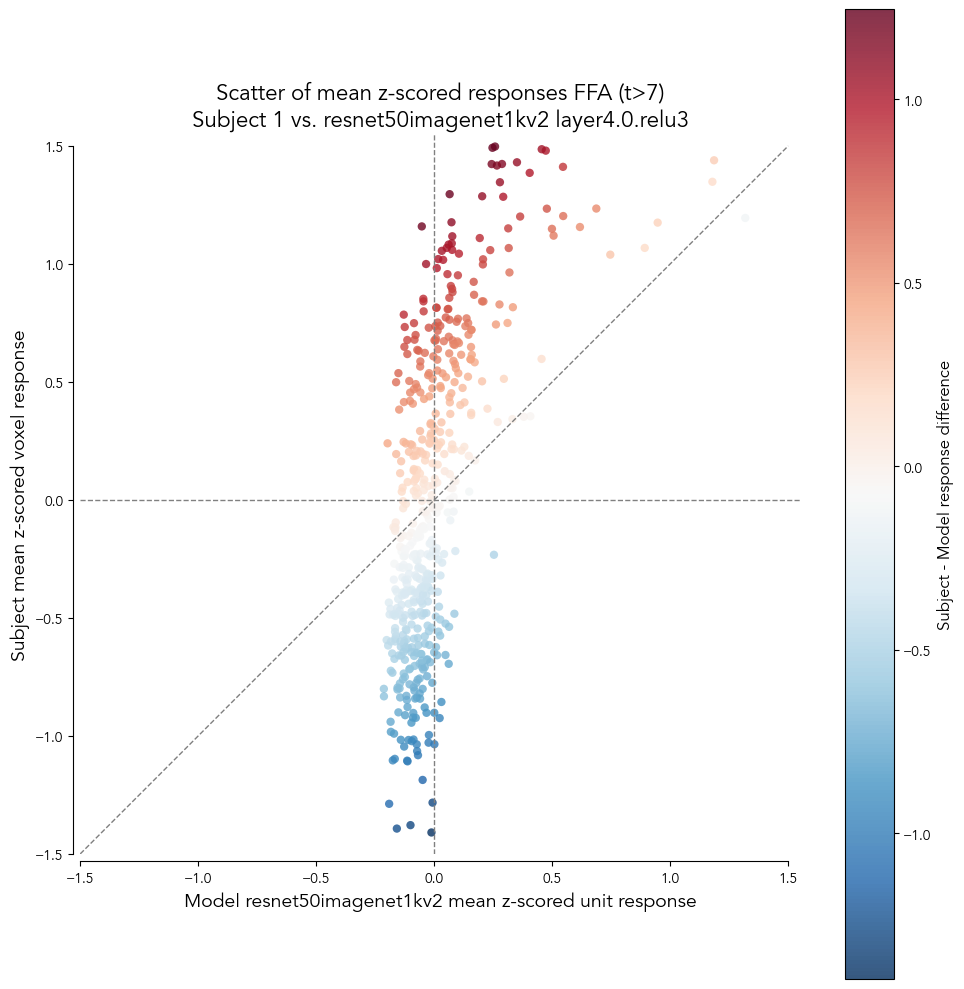

### Voxel/Unit-averaged responses: 9000 images

In [ ]:
subject = 1
froi = 'FFA'
subset = None # 515 for shared, None for subject-specific set
model_name = 'resnet50imagenet1kv2'

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
)

sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
    df=sbj_froi_mdl_subset_resp_df,
    images_np=stimuli_subset,
    x_col='model_response',
    y_col='subject_response',
    color_col='response_diff',
    info_cols=['labels', 'nsd_image_id'],
    output_path=None,  # Change to a file path to save as HTML
    title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
)

save_interactive_plot_as_html(
    plot=sbj_froi_mdl_subset_scatter,
    output_path=f'{PLOTS_DIR}/s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
)

### Voxel/Unit-averaged responses: Manually curated canonical face images (Try 1: Liberal choosing)

In [ ]:
subject = 1
froi = 'FFA'
subset = None # 515 for shared, None for subject-specific set
model_name = 'resnet50imagenet1kv2'

face_nsdids = person_face_nsdids + animal_face_nsdids

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
    nsdids=face_nsdids
)

# Show torchvision grid of first 25 and last 25 images from stimuli_subset
choice_indices = images_subset_df[images_subset_df['nsdId'].isin(person_face_nsdids[:15] + animal_face_nsdids[:15])].index.tolist()
plt.figure(figsize=(20, 12))
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[choice_indices]).permute(0, 3, 1, 2), nrow=15, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.title(f'Curated face images (n={len(stimuli_subset)}) for Subject {subject}', fontsize=16)
plt.show()
plt.close()

sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
    df=sbj_froi_mdl_subset_resp_df,
    images_np=stimuli_subset,
    x_col='model_response',
    y_col='subject_response',
    color_col='response_diff',
    info_cols=['labels', 'nsd_image_id'],
    output_path=None,  # Change to a file path to save as HTML
    title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
)

save_interactive_plot_as_html(
    plot=sbj_froi_mdl_subset_scatter,
    output_path=f'{PLOTS_DIR}/curatedfaces_s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
)

/tmp/ipykernel_734669/1022417727.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(data_to_plot, positions=x_pos, labels=labels, patch_artist=True, medianprops=dict(color='black'), widths=0.1)


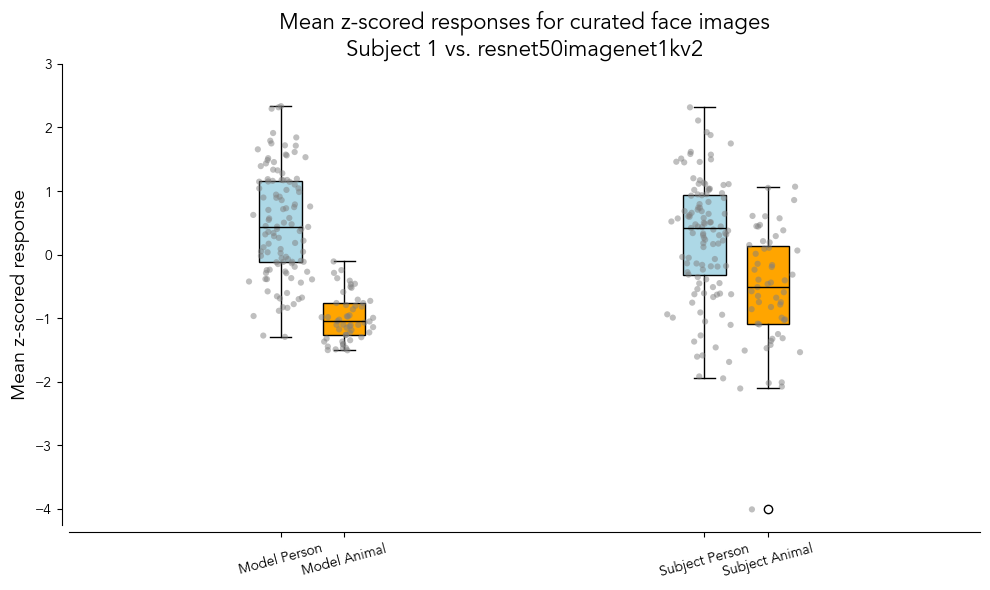

In [41]:
sbj_mean_data = sbj_froi_subset_data.mean(axis=-1).cpu().numpy()
mdl_mean_data = mdl_froi_subset_data.mean(axis=-1).cpu().numpy()
sbj_mean_data_zscored = (sbj_mean_data - sbj_mean_data.mean()) / sbj_mean_data.std()
mdl_mean_data_zscored = (mdl_mean_data - mdl_mean_data.mean()) / mdl_mean_data.std()

person_indices = images_subset_df[images_subset_df['nsdId'].isin(person_face_nsdids)].index
animal_indices = images_subset_df[images_subset_df['nsdId'].isin(animal_face_nsdids)].index

# Plot box plot of model person and animal respones, and subject person and animal responses
x_pos = [0.925, 1.075, 1.925, 2.075]
data_to_plot = [
    mdl_mean_data_zscored[person_indices],
    mdl_mean_data_zscored[animal_indices],
    sbj_mean_data_zscored[person_indices],
    sbj_mean_data_zscored[animal_indices],
]
labels = ['Model Person', 'Model Animal', 'Subject Person', 'Subject Animal']

plt.figure(figsize=(10, 6))
box = plt.boxplot(data_to_plot, positions=x_pos, labels=labels, patch_artist=True, medianprops=dict(color='black'), widths=0.1)
colors = ['lightblue', 'orange', 'lightblue', 'orange']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)

# Add jittered scatter points
for i, (data, pos) in enumerate(zip(data_to_plot, x_pos)):
    # Create jittered x-positions
    x_jitter = np.random.normal(pos, 0.03, size=len(data))
    plt.scatter(x_jitter, data, color='gray', alpha=0.5, s=20, edgecolor='none', zorder=2)

# Rotate x-tick labels
plt.tick_params(axis='x', rotation=15)

plt.ylabel('Mean z-scored response', fontsize=14)
plt.title(f'Mean z-scored responses for curated face images\nSubject {subject} vs. {model_name}', fontsize=16)
plt.ylim(-4.25, 3)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/subject_model_mean_zscored_response_boxplot_curatedfaces.png', dpi=300)
plt.show()
plt.close()

### Voxel/Unit-averaged responses: Manually curated canonical face images (Try 2: Conservative choosing from 1/3rd of the images)

In [ ]:
subject = 1
froi = 'FFA'
subset = None # 515 for shared, None for subject-specific set
model_name = 'resnet50imagenet1kv2'

conservative_person_face_nsdids = [
    1136, 1346, 2125, 7627, 8743, 12013, 12258, 14631, 15835, 16649, 18170, 19301, 19471, 21193, 21375
]
conservative_animal_face_nsdids = [
    1162, 1487, 2429, 2795, 3532, 4221, 4719, 5156, 6137, 6315, 8213, 8486, 8489, 8757, 8858, 10319, 11431, 12460, 15180,
    15555, 17505, 18569, 19079, 21064, 21723, 23796, 25131
]

bag1_info = {
    'label': 'Human Faces',
    'nsdids': conservative_person_face_nsdids
}
bag2_info = {
    'label': 'Animal Faces',
    'nsdids': conservative_animal_face_nsdids
}
print(f"{len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
    nsdids=bag1_info['nsdids'] + bag2_info['nsdids']
)
# Get indices of the nsdids in each bag
bag1_indices = images_subset_df[images_subset_df['nsdId'].isin(bag1_info['nsdids'])].index.tolist()
bag2_indices = images_subset_df[images_subset_df['nsdId'].isin(bag2_info['nsdids'])].index.tolist()

plt.figure(figsize=(20, 12))
plt.subplot(2, 1, 1)
plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag1_indices]).permute(0, 3, 1, 2), nrow=12, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.subplot(2, 1, 2)
plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag2_indices]).permute(0, 3, 1, 2), nrow=12, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
plt.tight_layout()
plt.show()
plt.close()

sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
    df=sbj_froi_mdl_subset_resp_df,
    images_np=stimuli_subset,
    x_col='model_response',
    y_col='subject_response',
    color_col='response_diff',
    info_cols=['labels', 'nsd_image_id'],
    output_path=None,  # Change to a file path to save as HTML
    title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
)

save_interactive_plot_as_html(
    plot=sbj_froi_mdl_subset_scatter,
    output_path=f'{PLOTS_DIR}/curatedimages_s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
)

sbj_mean_data = sbj_froi_subset_data.mean(axis=-1).cpu().numpy()
mdl_mean_data = mdl_froi_subset_data.mean(axis=-1).cpu().numpy()
sbj_mean_data_zscored = (sbj_mean_data - sbj_mean_data.mean()) / sbj_mean_data.std()
mdl_mean_data_zscored = (mdl_mean_data - mdl_mean_data.mean()) / mdl_mean_data.std()

# Plot box plot of model person and animal respones, and subject person and animal responses
x_pos = [0.925, 1.075, 1.925, 2.075]
data_to_plot = [
    mdl_mean_data_zscored[bag1_indices],
    mdl_mean_data_zscored[bag2_indices],
    sbj_mean_data_zscored[bag1_indices],
    sbj_mean_data_zscored[bag2_indices],
]

# Plot box plot of model and human responses to bag 1 and bag 2
sbj_mean_data = sbj_froi_subset_data.mean(axis=-1).cpu().numpy()
mdl_mean_data = mdl_froi_subset_data.mean(axis=-1).cpu().numpy()
sbj_mean_data_zscored = (sbj_mean_data - sbj_mean_data.mean()) / sbj_mean_data.std()
mdl_mean_data_zscored = (mdl_mean_data - mdl_mean_data.mean()) / mdl_mean_data.std()

# Plot box plot of model person and animal respones, and subject person and animal responses
x_pos = [0.925, 1.075, 1.925, 2.075]
plot_data = {
    'Model ' + bag1_info['label']: mdl_mean_data_zscored[bag1_indices],
    'Model ' + bag2_info['label']: mdl_mean_data_zscored[bag2_indices],
    'Subject ' + bag1_info['label']: sbj_mean_data_zscored[bag1_indices],
    'Subject ' + bag2_info['label']: sbj_mean_data_zscored[bag2_indices],
}

plt.figure(figsize=(10, 6))
box = plt.boxplot(list(plot_data.values()), positions=x_pos, patch_artist=True, medianprops=dict(color='black'), widths=0.1)
colors = ['lightblue', 'orange']
for patch, color in zip(box['boxes'], colors*2):
    patch.set_facecolor(color)
# Legend, make empty plots with colors
for color, label in zip(colors, [bag1_info['label'], bag2_info['label']]):
    plt.plot([], [], color=color, label=label, linewidth=10)
plt.legend(loc='best', frameon=False)

# Add jittered scatter points
for i, (data, pos) in enumerate(zip(data_to_plot, x_pos)):
    # Create jittered x-positions
    x_jitter = np.random.normal(pos, 0.03, size=len(data))
    plt.scatter(x_jitter, data, color='gray', alpha=0.5, s=20, edgecolor='none', zorder=2)

# Manual x-tick labels
plt.xticks([1, 2], ['Model', 'Subject'], rotation=15)

plt.ylabel('Mean z-scored response', fontsize=14)
plt.title(f'Mean z-scored responses for curated images\nSubject {subject} vs. {model_name}, froi" {froi}', fontsize=16)
ymin, ymax = np.concat(list(plot_data.values())).min(), np.concat(list(plot_data.values())).max()
plt.ylim(ymin*1.1, ymax*1.1)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(1, 2)
plt.gca().spines['left'].set_bounds(np.ceil(ymin), np.ceil(ymax))
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/subject_model_mean_zscored_response_boxplot_curatedfaces.png', dpi=300)
plt.show()
plt.close()

In [ ]:
subject = 1
froi = 'FFA'
subset = None # 515 for shared, None for subject-specific set
model_name = 'resnet50imagenet1kv2'

bag1_info = {
    'label': 'Human Faces',
    'nsdids': [
        1136, 1346, 2125, 7627, 8743, 12013, 12258, 14631, 15835, 16649, 18170, 19301, 19471, 21193, 21375
    ]
}
bag2_info = {
    'label': 'Animal Faces',
    'nsdids': [
        1162, 1487, 2429, 2795, 3532, 4221, 4719, 5156, 6137, 6315, 8213, 8486, 8489, 8757, 8858, 10319, 11431, 12460, 15180,
        15555, 17505, 18569, 19079, 21064, 21723, 23796, 25131
    ]
}
print(f"{len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
    nsdids=bag1_info['nsdids'] + bag2_info['nsdids']
)
# Get indices of the nsdids in each bag
bag1_indices = images_subset_df[images_subset_df['nsdId'].isin(bag1_info['nsdids'])].index.tolist()
bag2_indices = images_subset_df[images_subset_df['nsdId'].isin(bag2_info['nsdids'])].index.tolist()

plt.figure(figsize=(20, 12))
plt.subplot(2, 1, 1)
plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag1_indices]).permute(0, 3, 1, 2), nrow=12, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.subplot(2, 1, 2)
plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag2_indices]).permute(0, 3, 1, 2), nrow=12, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
plt.tight_layout()
plt.show()
plt.close()

sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
    df=sbj_froi_mdl_subset_resp_df,
    images_np=stimuli_subset,
    x_col='model_response',
    y_col='subject_response',
    color_col='response_diff',
    info_cols=['labels', 'nsd_image_id'],
    output_path=None,  # Change to a file path to save as HTML
    title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
)

save_interactive_plot_as_html(
    plot=sbj_froi_mdl_subset_scatter,
    output_path=f'{PLOTS_DIR}/curatedimages_s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
)


# Plot box plot of model person and animal respones, and subject person and animal responses
x_pos = [0.925, 1.075, 1.925, 2.075]
plot_data = {
    'Model ' + bag1_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["model_response"],
    'Model ' + bag2_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["model_response"],
    'Subject ' + bag1_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["subject_response"],
    'Subject ' + bag2_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["subject_response"],
}

plt.figure(figsize=(10, 6))
box = plt.boxplot(list(plot_data.values()), positions=x_pos, patch_artist=True, medianprops=dict(color='black'), widths=0.1)
colors = ['lightblue', 'orange']
for patch, color in zip(box['boxes'], colors*2):
    patch.set_facecolor(color)
# Legend, make empty plots with colors
for color, label in zip(colors, [bag1_info['label'], bag2_info['label']]):
    plt.plot([], [], color=color, label=label, linewidth=10)
plt.legend(loc='best', frameon=False)

# Add jittered scatter points
for i, (data, pos) in enumerate(zip(list(plot_data.values()), x_pos)):
    # Create jittered x-positions
    x_jitter = np.random.normal(pos, 0.03, size=len(data))
    plt.scatter(x_jitter, data, color='gray', alpha=0.5, s=20, edgecolor='none', zorder=2)

# Manual x-tick labels
plt.xticks([1, 2], ['Model', 'Subject'], rotation=15)

plt.ylabel('Mean z-scored response', fontsize=14)
plt.title(f'Mean z-scored responses for curated images\nSubject {subject} vs. {model_name}, froi: {froi}', fontsize=16)
ymin, ymax = np.concat(list(plot_data.values())).min(), np.concat(list(plot_data.values())).max()
plt.ylim(ymin*1.1, ymax*1.1)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(1, 2)
plt.gca().spines['left'].set_bounds(np.ceil(ymin), np.ceil(ymax))
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/subject_model_mean_zscored_response_boxplot_curatedfaces.png', dpi=300)
plt.show()
plt.close()

In [ ]:
subject = 1
froi = 'FFA'
subset = None # 515 for shared, None for subject-specific set
model_name = 'resnet50openaiclip'

bag1_info = {
    'label': 'Human Faces',
    'nsdids': [
        1136, 1346, 2125, 7627, 8743, 12013, 12258, 14631, 15835, 16649, 18170, 19301, 19471, 21193, 21375
    ]
}
bag2_info = {
    'label': 'Animal Faces',
    'nsdids': [
        1162, 1487, 2429, 2795, 3532, 4221, 4719, 5156, 6137, 6315, 8213, 8486, 8489, 8757, 8858, 10319, 11431, 12460, 15180,
        15555, 17505, 18569, 19079, 21064, 21723, 23796, 25131
    ]
}
print(f"{len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
    nsdids=bag1_info['nsdids'] + bag2_info['nsdids']
)
# Get indices of the nsdids in each bag
bag1_indices = images_subset_df[images_subset_df['nsdId'].isin(bag1_info['nsdids'])].index.tolist()
bag2_indices = images_subset_df[images_subset_df['nsdId'].isin(bag2_info['nsdids'])].index.tolist()

plt.figure(figsize=(20, 12))
plt.subplot(2, 1, 1)
plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag1_indices]).permute(0, 3, 1, 2), nrow=12, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.subplot(2, 1, 2)
plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag2_indices]).permute(0, 3, 1, 2), nrow=12, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
plt.tight_layout()
plt.show()
plt.close()

sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
    df=sbj_froi_mdl_subset_resp_df,
    images_np=stimuli_subset,
    x_col='model_response',
    y_col='subject_response',
    color_col='response_diff',
    info_cols=['labels', 'nsd_image_id'],
    output_path=None,  # Change to a file path to save as HTML
    title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
)

save_interactive_plot_as_html(
    plot=sbj_froi_mdl_subset_scatter,
    output_path=f'{PLOTS_DIR}/curatedimages_s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
)


# Plot box plot of model person and animal respones, and subject person and animal responses
x_pos = [0.925, 1.075, 1.925, 2.075]
plot_data = {
    'Model ' + bag1_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["model_response"],
    'Model ' + bag2_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["model_response"],
    'Subject ' + bag1_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["subject_response"],
    'Subject ' + bag2_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["subject_response"],
}

plt.figure(figsize=(10, 6))
box = plt.boxplot(list(plot_data.values()), positions=x_pos, patch_artist=True, medianprops=dict(color='black'), widths=0.1)
colors = ['lightblue', 'orange']
for patch, color in zip(box['boxes'], colors*2):
    patch.set_facecolor(color)
# Legend, make empty plots with colors
for color, label in zip(colors, [bag1_info['label'], bag2_info['label']]):
    plt.plot([], [], color=color, label=label, linewidth=10)
plt.legend(loc='best', frameon=False)

# Add jittered scatter points
for i, (data, pos) in enumerate(zip(list(plot_data.values()), x_pos)):
    # Create jittered x-positions
    x_jitter = np.random.normal(pos, 0.03, size=len(data))
    plt.scatter(x_jitter, data, color='gray', alpha=0.5, s=20, edgecolor='none', zorder=2)

# Manual x-tick labels
plt.xticks([1, 2], ['Model', 'Subject'], rotation=15)

plt.ylabel('Mean z-scored response', fontsize=14)
plt.title(f'Mean z-scored responses for curated images\nSubject {subject} vs. {model_name}, froi: {froi}', fontsize=16)
ymin, ymax = np.concat(list(plot_data.values())).min(), np.concat(list(plot_data.values())).max()
plt.ylim(ymin*1.1, ymax*1.1)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(1, 2)
plt.gca().spines['left'].set_bounds(np.ceil(ymin), np.ceil(ymax))
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/subject_model_mean_zscored_response_boxplot_curatedfaces.png', dpi=300)
plt.show()
plt.close()

In [ ]:
subject = 1
froi = 'FFA'
subset = None # 515 for shared, None for subject-specific set
model_name = 'alexnetipclref01'

bag1_info = {
    'label': 'Human Faces',
    'nsdids': [
        1136, 1346, 2125, 7627, 8743, 12013, 12258, 14631, 15835, 16649, 18170, 19301, 19471, 21193, 21375
    ]
}
bag2_info = {
    'label': 'Animal Faces',
    'nsdids': [
        1162, 1487, 2429, 2795, 3532, 4221, 4719, 5156, 6137, 6315, 8213, 8486, 8489, 8757, 8858, 10319, 11431, 12460, 15180,
        15555, 17505, 18569, 19079, 21064, 21723, 23796, 25131
    ]
}
print(f"{len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
    nsdids=bag1_info['nsdids'] + bag2_info['nsdids']
)
# Get indices of the nsdids in each bag
bag1_indices = images_subset_df[images_subset_df['nsdId'].isin(bag1_info['nsdids'])].index.tolist()
bag2_indices = images_subset_df[images_subset_df['nsdId'].isin(bag2_info['nsdids'])].index.tolist()

plt.figure(figsize=(20, 12))
plt.subplot(2, 1, 1)
plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag1_indices]).permute(0, 3, 1, 2), nrow=12, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.subplot(2, 1, 2)
plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag2_indices]).permute(0, 3, 1, 2), nrow=12, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
plt.tight_layout()
plt.show()
plt.close()

sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
    df=sbj_froi_mdl_subset_resp_df,
    images_np=stimuli_subset,
    x_col='model_response',
    y_col='subject_response',
    color_col='response_diff',
    info_cols=['labels', 'nsd_image_id'],
    output_path=None,  # Change to a file path to save as HTML
    title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
)

save_interactive_plot_as_html(
    plot=sbj_froi_mdl_subset_scatter,
    output_path=f'{PLOTS_DIR}/curatedimages_s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
)


# Plot box plot of model person and animal respones, and subject person and animal responses
x_pos = [0.925, 1.075, 1.925, 2.075]
plot_data = {
    'Model ' + bag1_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["model_response"],
    'Model ' + bag2_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["model_response"],
    'Subject ' + bag1_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["subject_response"],
    'Subject ' + bag2_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["subject_response"],
}

plt.figure(figsize=(10, 6))
box = plt.boxplot(list(plot_data.values()), positions=x_pos, patch_artist=True, medianprops=dict(color='black'), widths=0.1)
colors = ['lightblue', 'orange']
for patch, color in zip(box['boxes'], colors*2):
    patch.set_facecolor(color)
# Legend, make empty plots with colors
for color, label in zip(colors, [bag1_info['label'], bag2_info['label']]):
    plt.plot([], [], color=color, label=label, linewidth=10)
plt.legend(loc='best', frameon=False)

# Add jittered scatter points
for i, (data, pos) in enumerate(zip(list(plot_data.values()), x_pos)):
    # Create jittered x-positions
    x_jitter = np.random.normal(pos, 0.03, size=len(data))
    plt.scatter(x_jitter, data, color='gray', alpha=0.5, s=20, edgecolor='none', zorder=2)

# Manual x-tick labels
plt.xticks([1, 2], ['Model', 'Subject'], rotation=15)

plt.ylabel('Mean z-scored response', fontsize=14)
plt.title(f'Mean z-scored responses for curated images\nSubject {subject} vs. {model_name}, froi: {froi}', fontsize=16)
ymin, ymax = np.concat(list(plot_data.values())).min(), np.concat(list(plot_data.values())).max()
plt.ylim(ymin*1.1, ymax*1.1)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(1, 2)
plt.gca().spines['left'].set_bounds(np.ceil(ymin), np.ceil(ymax))
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/subject_model_mean_zscored_response_boxplot_curatedfaces.png', dpi=300)
plt.show()
plt.close()

# EBA (s1 vs. RN50-ImgNet)

## Voxel/Unit-averaged responses: 515 images

In [ ]:
subject = 1
froi = 'EBA'
subset = 515 # 515 for shared, None for subject-specific set
model_name = 'resnet50imagenet1kv2'

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
)

sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
    df=sbj_froi_mdl_subset_resp_df,
    images_np=stimuli_subset,
    x_col='model_response',
    y_col='subject_response',
    color_col='response_diff',
    info_cols=['labels', 'nsd_image_id'],
    output_path=None,  # Change to a file path to save as HTML
    title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
)

save_interactive_plot_as_html(
    plot=sbj_froi_mdl_subset_scatter,
    output_path=f'{PLOTS_DIR}/s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
)

In [6]:
sbj_froi_mdl_subset_resp_df[
    sbj_froi_mdl_subset_resp_df['nsd_image_id'] == 21192
]

,idx,nsd_image_id,subject_response,model_response,response_diff,labels
126,126,21192,-0.472632,0.147118,-0.61975,"[tie, person]"


In [ ]:
subject = 1
froi = 'EBA'
subset = 515 # 515 for shared, None for subject-specific set
model_name = 'resnet50imagenet1kv2'

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
)

sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
    df=sbj_froi_mdl_subset_resp_df,
    images_np=stimuli_subset,
    x_col='model_response',
    y_col='subject_response',
    color_col='response_diff',
    info_cols=['labels', 'nsd_image_id'],
    output_path=None,  # Change to a file path to save as HTML
    title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
)

save_interactive_plot_as_html(
    plot=sbj_froi_mdl_subset_scatter,
    output_path=f'{PLOTS_DIR}/s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
)

## Voxel/Unit-averaged responses: 9000 images

In [ ]:
subject = 1
froi = 'EBA'
subset = None # 515 for shared, None for subject-specific set
model_name = 'resnet50imagenet1kv2'

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
)

sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
    df=sbj_froi_mdl_subset_resp_df,
    images_np=stimuli_subset,
    x_col='model_response',
    y_col='subject_response',
    color_col='response_diff',
    info_cols=['labels', 'nsd_image_id'],
    output_path=None,  # Change to a file path to save as HTML
    title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
)

save_interactive_plot_as_html(
    plot=sbj_froi_mdl_subset_scatter,
    output_path=f'{PLOTS_DIR}/s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
)

## Voxel/Unit-averaged responses: Manually curated canonical face images

In [ ]:
subject = 1
froi = 'EBA'
subset = None # 515 for shared, None for subject-specific set
model_name = 'resnet50imagenet1kv2'

face_nsdids = person_face_nsdids + animal_face_nsdids

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
    nsdids=face_nsdids
)

# Show torchvision grid of first 25 and last 25 images from stimuli_subset
choice_indices = images_subset_df[images_subset_df['nsdId'].isin(person_face_nsdids[:15] + animal_face_nsdids[:15])].index.tolist()
plt.figure(figsize=(20, 12))
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[choice_indices]).permute(0, 3, 1, 2), nrow=15, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.title(f'Curated face images (n={len(stimuli_subset)}) for Subject {subject}', fontsize=16)
plt.show()
plt.close()

sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
    df=sbj_froi_mdl_subset_resp_df,
    images_np=stimuli_subset,
    x_col='model_response',
    y_col='subject_response',
    color_col='response_diff',
    info_cols=['labels', 'nsd_image_id'],
    output_path=None,  # Change to a file path to save as HTML
    title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
)

save_interactive_plot_as_html(
    plot=sbj_froi_mdl_subset_scatter,
    output_path=f'{PLOTS_DIR}/curatedfaces_s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
)

/tmp/ipykernel_734669/1238637683.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(data_to_plot, positions=x_pos, labels=labels, patch_artist=True, medianprops=dict(color='black'), widths=0.1)


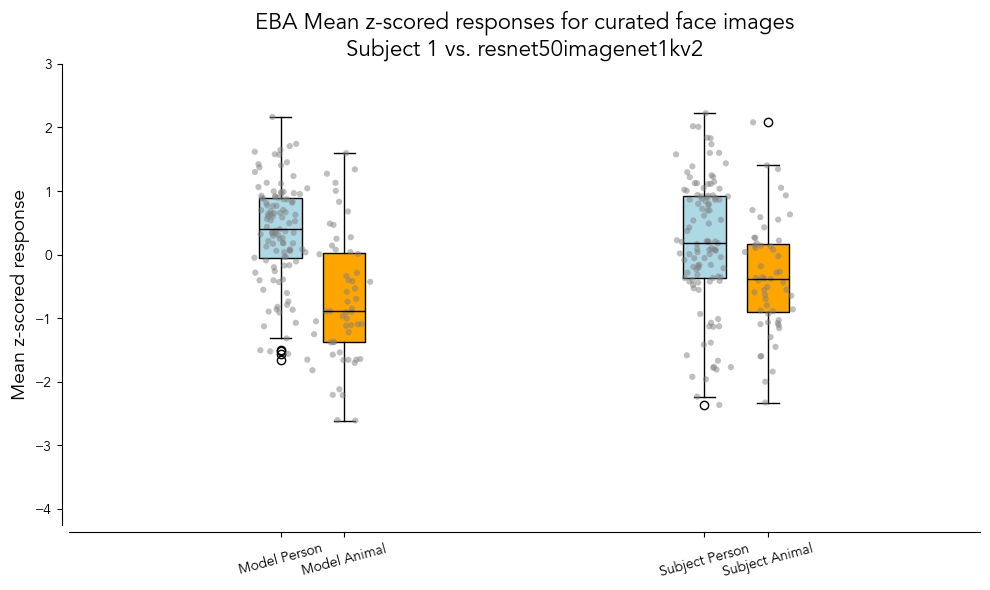

In [46]:
sbj_mean_data = sbj_froi_subset_data.mean(axis=-1).cpu().numpy()
mdl_mean_data = mdl_froi_subset_data.mean(axis=-1).cpu().numpy()
sbj_mean_data_zscored = (sbj_mean_data - sbj_mean_data.mean()) / sbj_mean_data.std()
mdl_mean_data_zscored = (mdl_mean_data - mdl_mean_data.mean()) / mdl_mean_data.std()

person_indices = images_subset_df[images_subset_df['nsdId'].isin(person_face_nsdids)].index
animal_indices = images_subset_df[images_subset_df['nsdId'].isin(animal_face_nsdids)].index

# Plot box plot of model person and animal respones, and subject person and animal responses
x_pos = [0.925, 1.075, 1.925, 2.075]
data_to_plot = [
    mdl_mean_data_zscored[person_indices],
    mdl_mean_data_zscored[animal_indices],
    sbj_mean_data_zscored[person_indices],
    sbj_mean_data_zscored[animal_indices],
]
labels = ['Model Person', 'Model Animal', 'Subject Person', 'Subject Animal']

plt.figure(figsize=(10, 6))
box = plt.boxplot(data_to_plot, positions=x_pos, labels=labels, patch_artist=True, medianprops=dict(color='black'), widths=0.1)
colors = ['lightblue', 'orange', 'lightblue', 'orange']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)

# Add jittered scatter points
for i, (data, pos) in enumerate(zip(data_to_plot, x_pos)):
    # Create jittered x-positions
    x_jitter = np.random.normal(pos, 0.03, size=len(data))
    plt.scatter(x_jitter, data, color='gray', alpha=0.5, s=20, edgecolor='none', zorder=2)

# Rotate x-tick labels
plt.tick_params(axis='x', rotation=15)

plt.ylabel('Mean z-scored response', fontsize=14)
plt.title(f'{froi} Mean z-scored responses for curated face images\nSubject {subject} vs. {model_name}', fontsize=16)
plt.ylim(-4.25, 3)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/subject_model_mean_zscored_response_boxplot_curatedfaces.png', dpi=300)
plt.show()
plt.close()

## Voxel/Unit-averaged responses: Manually curated canonical body images (1/3rd of images)

In [ ]:
subject = 1
froi = 'EBA'
subset = None # 515 for shared, None for subject-specific set
model_name = 'resnet50imagenet1kv2'

bag1_info = {
    'label': 'Human Bodies',
    'nsdids': [
        200, 1512, 3585, 6094, 6750, 8391, 11018, 11668, 12225, 12316, 12469, 12713, 15718, 15816,
        16678, 18373, 18315, 26020, 26457
    ]
}
bag2_info = {
    'label': 'Animal Bodies',
    'nsdids': [
        1378, 4685, 6461, 6555, 11611, 11696, 12490, 15739, 18605, 19091, 19428, 19736, 20040,
        20097, 20389, 20908, 21755
    ]
}
print(f"{len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
    nsdids=bag1_info['nsdids'] + bag2_info['nsdids']
)
# Get indices of the nsdids in each bag
bag1_indices = images_subset_df[images_subset_df['nsdId'].isin(bag1_info['nsdids'])].index.tolist()
bag2_indices = images_subset_df[images_subset_df['nsdId'].isin(bag2_info['nsdids'])].index.tolist()

plt.figure(figsize=(20, 12))
plt.subplot(2, 1, 1)
plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag1_indices]).permute(0, 3, 1, 2), nrow=12, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.subplot(2, 1, 2)
plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag2_indices]).permute(0, 3, 1, 2), nrow=12, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
plt.tight_layout()
plt.show()
plt.close()

sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
    df=sbj_froi_mdl_subset_resp_df,
    images_np=stimuli_subset,
    x_col='model_response',
    y_col='subject_response',
    color_col='response_diff',
    info_cols=['labels', 'nsd_image_id'],
    output_path=None,  # Change to a file path to save as HTML
    title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
)

save_interactive_plot_as_html(
    plot=sbj_froi_mdl_subset_scatter,
    output_path=f'{PLOTS_DIR}/curatedimages_s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
)


# Plot box plot of model person and animal respones, and subject person and animal responses
x_pos = [0.925, 1.075, 1.925, 2.075]
plot_data = {
    'Model ' + bag1_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["model_response"],
    'Model ' + bag2_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["model_response"],
    'Subject ' + bag1_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["subject_response"],
    'Subject ' + bag2_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["subject_response"],
}

plt.figure(figsize=(10, 6))
box = plt.boxplot(list(plot_data.values()), positions=x_pos, patch_artist=True, medianprops=dict(color='black'), widths=0.1)
colors = ['lightblue', 'orange']
for patch, color in zip(box['boxes'], colors*2):
    patch.set_facecolor(color)
# Legend, make empty plots with colors
for color, label in zip(colors, [bag1_info['label'], bag2_info['label']]):
    plt.plot([], [], color=color, label=label, linewidth=10)
plt.legend(loc='best', frameon=False)

# Add jittered scatter points
for i, (data, pos) in enumerate(zip(list(plot_data.values()), x_pos)):
    # Create jittered x-positions
    x_jitter = np.random.normal(pos, 0.03, size=len(data))
    plt.scatter(x_jitter, data, color='gray', alpha=0.5, s=20, edgecolor='none', zorder=2)

# Manual x-tick labels
plt.xticks([1, 2], ['Model', 'Subject'], rotation=15)

plt.ylabel('Mean z-scored response', fontsize=14)
plt.title(f'Mean z-scored responses for curated images\nSubject {subject} vs. {model_name}, froi: {froi}', fontsize=16)
ymin, ymax = np.concat(list(plot_data.values())).min(), np.concat(list(plot_data.values())).max()
plt.ylim(ymin*1.1, ymax*1.1)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(1, 2)
plt.gca().spines['left'].set_bounds(np.ceil(ymin), np.ceil(ymax))
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/subject_model_mean_zscored_response_boxplot_curatedfaces.png', dpi=300)
plt.show()
plt.close()

## Voxel/Unit-averaged responses: Manually curated canonical body images (Using cortex responses)

In [ ]:
subject = 1
froi = 'EBA'
subset = None # 515 for shared, None for subject-specific set
model_name = 'resnet50imagenet1kv2'

bag1_info = {
    'label': 'Human Bodies',
    'nsdids': [
        1512, 3644, 6653, 6452, 8503, 10831, 9774, 11936, 11668, 12225, 12469, 18011, 15718, 16846, 
        14841, 16678, 14738, 23613, 22133, 20263, 27144, 20545, 23538, 22828, 28138, 20541, 28690, 
        31280, 36557, 33495, 37128, 43345, 41563, 40001, 37621, 51914, 52447, 48202, 47272, 51008,
        49530, 57460, 59576, 65647, 71502
    ]
}
bag2_info = {
    'label': 'Animal Bodies',
    'nsdids': [
        103, 104, 15240, 15536, 19736, 11611, 6793, 21755, 4685, 1378, 13106, 11949, 9452, 
        14883, 20034, 13377, 20049, 5683, 12490, 6022, 25368, 13299, 6555, 12010, 31106, 46990,
        43162, 31415, 34318, 52060, 34030, 50981, 42749, 49170, 35049, 47918, 37954, 57114, 72710,
        65005, 54552, 63396, 53402, 67649, 68896
    ]
}
print(f"{len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
    nsdids=bag1_info['nsdids'] + bag2_info['nsdids']
)
# Get indices of the nsdids in each bag
bag1_indices = images_subset_df[images_subset_df['nsdId'].isin(bag1_info['nsdids'])].index.tolist()
bag2_indices = images_subset_df[images_subset_df['nsdId'].isin(bag2_info['nsdids'])].index.tolist()

plt.figure(figsize=(20, 12))
plt.subplot(2, 1, 1)
plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag1_indices]).permute(0, 3, 1, 2), nrow=12, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.subplot(2, 1, 2)
plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag2_indices]).permute(0, 3, 1, 2), nrow=12, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
plt.tight_layout()
plt.show()
plt.close()

sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
    df=sbj_froi_mdl_subset_resp_df,
    images_np=stimuli_subset,
    x_col='model_response',
    y_col='subject_response',
    color_col='response_diff',
    info_cols=['labels', 'nsd_image_id'],
    output_path=None,  # Change to a file path to save as HTML
    title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
)

save_interactive_plot_as_html(
    plot=sbj_froi_mdl_subset_scatter,
    output_path=f'{PLOTS_DIR}/curatedimages_s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
)


# Plot box plot of model person and animal respones, and subject person and animal responses
x_pos = [0.925, 1.075, 1.925, 2.075]
plot_data = {
    'Model ' + bag1_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["model_response"],
    'Model ' + bag2_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["model_response"],
    'Subject ' + bag1_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["subject_response"],
    'Subject ' + bag2_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["subject_response"],
}

plt.figure(figsize=(10, 6))
box = plt.boxplot(list(plot_data.values()), positions=x_pos, patch_artist=True, medianprops=dict(color='black'), widths=0.1)
colors = ['lightblue', 'orange']
for patch, color in zip(box['boxes'], colors*2):
    patch.set_facecolor(color)
# Legend, make empty plots with colors
for color, label in zip(colors, [bag1_info['label'], bag2_info['label']]):
    plt.plot([], [], color=color, label=label, linewidth=10)
plt.legend(loc='best', frameon=False)

# Add jittered scatter points
for i, (data, pos) in enumerate(zip(list(plot_data.values()), x_pos)):
    # Create jittered x-positions
    x_jitter = np.random.normal(pos, 0.03, size=len(data))
    plt.scatter(x_jitter, data, color='gray', alpha=0.5, s=20, edgecolor='none', zorder=2)

# Manual x-tick labels
plt.xticks([1, 2], ['Model', 'Subject'], rotation=15)

plt.ylabel('Mean z-scored response', fontsize=14)
plt.title(f'Mean z-scored responses for curated images\nSubject {subject} vs. {model_name}, froi: {froi}', fontsize=16)
ymin, ymax = np.concat(list(plot_data.values())).min(), np.concat(list(plot_data.values())).max()
plt.ylim(ymin*1.1, ymax*1.1)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(1, 2)
plt.gca().spines['left'].set_bounds(np.ceil(ymin), np.ceil(ymax))
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/subject_model_mean_zscored_response_boxplot_curatedfaces.png', dpi=300)
plt.show()
plt.close()

In [7]:
import scipy.stats as stats
print(stats.ttest_ind(
    sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["subject_response"],
    sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["subject_response"],
    equal_var=False
))
print(stats.ttest_ind(
    sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["model_response"],
    sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["model_response"],
    equal_var=False
))

TtestResult(statistic=np.float64(6.580848044141734), pvalue=np.float64(3.386896329460468e-09), df=np.float64(86.9346075495858))
TtestResult(statistic=np.float64(5.215657973950588), pvalue=np.float64(1.2682335105633995e-06), df=np.float64(85.13648069147813))


# PPA (s1 vs. RN50-ImgNet)

### Voxel/Unit-averaged responses: 515 images

In [ ]:
subject = 1
froi = 'PPA'
subset = 515 # 515 for shared, None for subject-specific set
model_name = 'resnet50imagenet1kv2'

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
)

sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
    df=sbj_froi_mdl_subset_resp_df,
    images_np=stimuli_subset,
    x_col='model_response',
    y_col='subject_response',
    color_col='response_diff',
    info_cols=['labels', 'nsd_image_id'],
    output_path=None,  # Change to a file path to save as HTML
    title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
)

save_interactive_plot_as_html(
    plot=sbj_froi_mdl_subset_scatter,
    output_path=f'{PLOTS_DIR}/s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
)

### Voxel/Unit-averaged responses: 9000 images

In [ ]:
subject = 1
froi = 'PPA'
subset = None # 515 for shared, None for subject-specific set
model_name = 'resnet50imagenet1kv2'

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
)

sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
    df=sbj_froi_mdl_subset_resp_df,
    images_np=stimuli_subset,
    x_col='model_response',
    y_col='subject_response',
    color_col='response_diff',
    info_cols=['labels', 'nsd_image_id'],
    output_path=None,  # Change to a file path to save as HTML
    title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
)

save_interactive_plot_as_html(
    plot=sbj_froi_mdl_subset_scatter,
    output_path=f'{PLOTS_DIR}/s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
)

### Voxel/Unit-averaged responses: Manually curated canonical scene images

In [ ]:
subject = 1
froi = 'PPA'
subset = None # 515 for shared, None for subject-specific set
model_name = 'resnet50imagenet1kv2'

bag1_info = {
    'label': 'Liminal Scenes',
    'nsdids': [
        222, 3016, 3803, 5237, 7354, 7355, 7360, 8910, 10227, 10929, 11376, 11618, 18312, 19592,
        20171, 21069, 21394, 22531, 23018
    ]
}
bag2_info = {
    'label': 'Typical Scenes',
    'nsdids': [
        1309, 452, 513, 1510, 2655, 13439, 13632, 20243, 20308, 20397, 20493
    ]
}
print(f"{len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
    nsdids=bag1_info['nsdids'] + bag2_info['nsdids']
)
# Get indices of the nsdids in each bag
bag1_indices = images_subset_df[images_subset_df['nsdId'].isin(bag1_info['nsdids'])].index.tolist()
bag2_indices = images_subset_df[images_subset_df['nsdId'].isin(bag2_info['nsdids'])].index.tolist()

plt.figure(figsize=(20, 12))
plt.subplot(2, 1, 1)
plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag1_indices]).permute(0, 3, 1, 2), nrow=12, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.subplot(2, 1, 2)
plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag2_indices]).permute(0, 3, 1, 2), nrow=12, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
plt.tight_layout()
plt.show()
plt.close()

sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
    df=sbj_froi_mdl_subset_resp_df,
    images_np=stimuli_subset,
    x_col='model_response',
    y_col='subject_response',
    color_col='response_diff',
    info_cols=['labels', 'nsd_image_id'],
    output_path=None,  # Change to a file path to save as HTML
    title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
)

save_interactive_plot_as_html(
    plot=sbj_froi_mdl_subset_scatter,
    output_path=f'{PLOTS_DIR}/curatedimages_s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
)


# Plot box plot of model person and animal respones, and subject person and animal responses
x_pos = [0.925, 1.075, 1.925, 2.075]
plot_data = {
    'Model ' + bag1_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["model_response"],
    'Model ' + bag2_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["model_response"],
    'Subject ' + bag1_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["subject_response"],
    'Subject ' + bag2_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["subject_response"],
}

plt.figure(figsize=(10, 6))
box = plt.boxplot(list(plot_data.values()), positions=x_pos, patch_artist=True, medianprops=dict(color='black'), widths=0.1)
colors = ['lightblue', 'orange']
for patch, color in zip(box['boxes'], colors*2):
    patch.set_facecolor(color)
# Legend, make empty plots with colors
for color, label in zip(colors, [bag1_info['label'], bag2_info['label']]):
    plt.plot([], [], color=color, label=label, linewidth=10)
plt.legend(loc='best', frameon=False)

# Add jittered scatter points
for i, (data, pos) in enumerate(zip(list(plot_data.values()), x_pos)):
    # Create jittered x-positions
    x_jitter = np.random.normal(pos, 0.03, size=len(data))
    plt.scatter(x_jitter, data, color='gray', alpha=0.5, s=20, edgecolor='none', zorder=2)

# Manual x-tick labels
plt.xticks([1, 2], ['Model', 'Subject'], rotation=15)

plt.ylabel('Mean z-scored response', fontsize=14)
plt.title(f'Mean z-scored responses for curated images\nSubject {subject} vs. {model_name}, froi: {froi}', fontsize=16)
ymin, ymax = np.concat(list(plot_data.values())).min(), np.concat(list(plot_data.values())).max()
plt.ylim(ymin*1.1, ymax*1.1)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(1, 2)
plt.gca().spines['left'].set_bounds(np.ceil(ymin), np.ceil(ymax))
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/subject_model_mean_zscored_response_boxplot_curatedfaces.png', dpi=300)
plt.show()
plt.close()